#DAY 1 : Understanding Data from the Iron Ore Flotation Process

Notebook ini adalah pintu masuk Saya ke dunia **analitik pertambangan** — memakai data untuk membantu keputusan operasi tambang & pengolahan bijih.


Saya akan belajar "berkenalan" dengan sebuah dataset industri: membukanya, melihat isinya, dan menarik kesimpulan awal — semua memakai **data nyata** dari sebuah pabrik flotasi bijih besi.

🎯 **Tujuan Pembelajaran**
> - Memahami apa itu `DataFrame` (tabel data di Python).
> - Membuka & membaca data proses tambang dengan **pandas**.
> - Melihat ringkasan data: `head`, `shape`, `info`, `describe`.
> - Memfilter & menghitung data sederhana (mis. kapan kadar pengotor tinggi).
> - Membuat visualisasi pertama untuk memahami kualitas hasil flotasi.

## About Dataset

Saya akan memakai **Quality Prediction in a Mining Process** — data nyata dari **pabrik flotasi bijih besi** milik sebuah perusahaan tambang (Vale, Brasil), direkam sepanjang Maret–September 2017.

**Apa itu flotasi?** Flotasi adalah proses untuk **memurnikan bijih besi**: bijih dicampur air jadi bubur (*pulp*), lalu ditambahkan reagen kimia (*amina*, *pati/starch*) dan udara sehingga pengotor — terutama **silika (SiO₂)** — terangkat sebagai busa dan bisa dibuang. Keluaran prosesnya adalah **konsentrat** dengan kadar besi lebih tinggi dan **kadar silika lebih rendah**. Semakin rendah `% Silica Concentrate`, semakin **bersih** produknya — itulah yang ingin kita pahami.

- **Sumber:** [Kaggle — edumagalhaes/quality-prediction-in-a-mining-process](https://www.kaggle.com/datasets/edumagalhaes/quality-prediction-in-a-mining-process)
- **Ukuran asli:** 737.453 baris × 24 kolom (sampel tiap 20 detik). Kita **ambil sampel 30.000 baris** agar ringan & cepat (data tetap nyata, hanya lebih sedikit).

| Kolom | Arti |
|-------|------|
| `% Iron Feed` | Kadar besi pada bijih **masuk** (umpan) |
| `% Silica Feed` | Kadar silika (pengotor) pada bijih **masuk** |
| `Starch Flow` | Aliran reagen pati/*starch* (**depresan bijih besi/hematit** — menahan besi agar tak ikut terangkat) |
| `Amina Flow` | Aliran reagen amina (**kolektor silika** — mengikat silika agar terangkat sebagai busa) |
| `Ore Pulp pH` | Keasaman bubur bijih |
| `Ore Pulp Density` | Kepadatan bubur bijih |
| `Flotation Column 01–07 Air Flow` | Aliran udara tiap kolom flotasi |
| `Flotation Column 01–07 Level` | Tinggi cairan tiap kolom flotasi |
| `% Iron Concentrate` | Kadar besi pada **hasil** (konsentrat) |
| `% Silica Concentrate` | Kadar silika pada **hasil** ← **fokus kita** (makin kecil makin baik) |

*Catatan: `date` bertipe teks (stempel waktu). Angka memakai **koma desimal**, jadi saat memuat kita set `decimal=","`.*

## Import Library

Saya akan menggunakan "peralatan" yang dibutuhkan:
- **pandas** → membaca & mengolah data berbentuk tabel.
- **numpy** → operasi angka/array.
- **matplotlib** & **seaborn** → membuat grafik.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Import Dataset

In [2]:
!pip install kaggle
!mkdir ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json
!kaggle datasets download -d edumagalhaes/quality-prediction-in-a-mining-process

cp: cannot stat 'kaggle.json': No such file or directory
chmod: cannot access '/root/.kaggle/kaggle.json': No such file or directory
Dataset URL: https://www.kaggle.com/datasets/edumagalhaes/quality-prediction-in-a-mining-process
License(s): CC0-1.0
100% 50.9M/50.9M [00:00<00:00, 122MB/s] 



## Early Exploration Dataset

In [13]:
df = pd.read_csv('quality-prediction-in-a-mining-process.zip', decimal=',')

Langkah pertama saat menerima data adalah **melihat-lihat** isinya.

Mari mulai dengan `head()` untuk menampilkan 5 baris pertama.

In [14]:
df.head()

,date,% Iron Feed,% Silica Feed,Starch Flow,Amina Flow,Ore Pulp Flow,Ore Pulp pH,Ore Pulp Density,Flotation Column 01 Air Flow,Flotation Column 02 Air Flow,...,Flotation Column 07 Air Flow,Flotation Column 01 Level,Flotation Column 02 Level,Flotation Column 03 Level,Flotation Column 04 Level,Flotation Column 05 Level,Flotation Column 06 Level,Flotation Column 07 Level,% Iron Concentrate,% Silica Concentrate
0,2017-03-10 01:00:00,55.2,16.98,3019.53,557.434,395.713,10.0664,1.74,249.214,253.235,...,250.884,457.396,432.962,424.954,443.558,502.255,446.370,523.344,66.91,1.31
1,2017-03-10 01:00:00,55.2,16.98,3024.41,563.965,397.383,10.0672,1.74,249.719,250.532,...,248.994,451.891,429.560,432.939,448.086,496.363,445.922,498.075,66.91,1.31
2,2017-03-10 01:00:00,55.2,16.98,3043.46,568.054,399.668,10.0680,1.74,249.741,247.874,...,248.071,451.240,468.927,434.610,449.688,484.411,447.826,458.567,66.91,1.31
3,2017-03-10 01:00:00,55.2,16.98,3047.36,568.665,397.939,10.0689,1.74,249.917,254.487,...,251.147,452.441,458.165,442.865,446.210,471.411,437.690,427.669,66.91,1.31
4,2017-03-10 01:00:00,55.2,16.98,3033.69,558.167,400.254,10.0697,1.74,250.203,252.136,...,248.928,452.441,452.900,450.523,453.670,462.598,443.682,425.679,66.91,1.31


**Interpretation:**

- Setiap baris adalah satu **cuplikan proses** (rekaman sensor pada satu waktu).
- Ada kolom kondisi umpan (`% Iron Feed`, `% Silica Feed`), setelan reagen & proses (`Starch Flow`, `Amina Flow`, `Ore Pulp pH`), kondisi tiap kolom flotasi, dan dua kolom **hasil akhir** (`% Iron Concentrate`, `% Silica Concentrate`).

Yang paling ingin kita tekan adalah `% Silica Concentrate`.

In [15]:
# Ukuran data: (jumlah baris, jumlah kolom)
print(df.shape)

(737453, 24)


In [16]:
#Ambil sample hanya 30000 baris
data = df.sample(30000, random_state=42).reset_index(drop=True)
print(f'Bentuk data yang digunakan: {data.shape}')

Bentuk data yang digunakan: (30000, 24)


**Interpretation:**
- dari total 737453 baris, saya akan menggunakan hanya 30000 data sample untuk kasus ini dengan 24 kolom (parameter)

In [17]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 24 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   date                          30000 non-null  object 
 1   % Iron Feed                   30000 non-null  float64
 2   % Silica Feed                 30000 non-null  float64
 3   Starch Flow                   30000 non-null  float64
 4   Amina Flow                    30000 non-null  float64
 5   Ore Pulp Flow                 30000 non-null  float64
 6   Ore Pulp pH                   30000 non-null  float64
 7   Ore Pulp Density              30000 non-null  float64
 8   Flotation Column 01 Air Flow  30000 non-null  float64
 9   Flotation Column 02 Air Flow  30000 non-null  float64
 10  Flotation Column 03 Air Flow  30000 non-null  float64
 11  Flotation Column 04 Air Flow  30000 non-null  float64
 12  Flotation Column 05 Air Flow  30000 non-null  float64
 13  F

Saya melihat dataset ini berisi **30.000 catatan** dengan **24 kolom** yang merekam **proses pemurnian bijih besi**.

Dari ringkasan ini, saya menangkap beberapa poin utama:

* **Data lengkap (0 kosong):** Semua kolom terisi penuh sebanyak 30.000 baris, jadi saya tidak perlu repot menangani data yang hilang di tahap awal.
* **Tipe data:** Ada 1 kolom waktu (`date`, yang formatnya masih teks) dan 23 kolom angka desimal (`float64`).
* **Alur proses yang terekam:**
  * **Awal (`Feed`):** Saya bisa melihat kadar besi dan silika (pengotor) sebelum diproses.
  * **Proses (`Starch`, `Amina`, `Ore Pulp`, `Air Flow`, `Level`):** Bagian ini mencatat pengaturan bahan kimia, kondisi campuran bijih, aliran udara, dan ketinggian di 7 kolom flotasi.
  * **Hasil (`Concentrate`):** Ini menunjukkan kadar besi dan silika akhir setelah diproses—biasanya bagian inilah yang saya jadikan target prediksi.



Sebagai langkah awal sebelum masuk ke analisis lebih dalam, saya perlu mengubah kolom `date` ke format tanggal yang benar, lalu mengecek apakah ada angka yang tidak wajar atau *outlier*.

In [18]:
data.describe().T

,count,mean,std,min,25%,50%,75%,max
% Iron Feed,30000.0,56.300114,5.145923,42.740000,52.670000,56.08000,59.720000,65.780000
% Silica Feed,30000.0,14.637822,6.790615,1.310000,8.940000,13.85000,19.550000,33.400000
Starch Flow,30000.0,2889.406537,1210.197703,0.024922,2093.655000,3036.10000,3746.045000,6294.940000
Amina Flow,30000.0,489.037615,91.421882,241.773313,433.030250,504.88300,553.705000,739.538000
Ore Pulp Flow,30000.0,397.595749,9.690155,376.255000,394.226750,399.17400,402.963250,418.636000
Ore Pulp pH,30000.0,9.771676,0.387785,8.753372,9.529018,9.80326,10.043800,10.808063
Ore Pulp Density,30000.0,1.680916,0.068982,1.519830,1.648697,1.69835,1.728422,1.853175
Flotation Column 01 Air Flow,30000.0,280.494691,29.256015,175.510000,250.313000,299.36900,300.148000,368.981531
Flotation Column 02 Air Flow,30000.0,277.639274,29.977939,176.164947,250.488000,296.42300,300.795000,375.654000
Flotation Column 03 Air Flow,30000.0,281.423905,28.209054,176.550680,250.928000,298.68600,300.405000,349.387000


**Interpretation:**

Secara singkat, ini yang saya tangkap dari angka-angka diatas:

* **Bahan baku (`Feed`):**
  - Kadar besi masuk rata-rata **56,3%**,
  - kadar silika (pengotor) cukup bervariasi dari **1,3% sampai 33,4%**. Jadi kualitas bijih awal naik-turun.

* **Proses:** `Starch Flow` paling sering diubah-ubah (dari hampir **0** sampai **6.295**). Kondisi `Ore Pulp` dan `Air Flow` di kolom 4–5 cukup stabil, sedangkan `Air Flow` di kolom lain dan `Level` tiap kolom cukup banyak bergerak.

* **Hasil (`Concentrate`):**
  - Kadar besi akhir konsisten di sekitar **65%**.
  - Kadar silika akhir umumnya rendah (median **1,99%**), tapi kadang sempat naik sampai **5,53%**.

Intinya, menurut saya hasil besi sudah cukup stabil, sementara silika akhir masih sesekali melonjak dan perlu dipantau.

In [19]:
data.isnull().sum().sort_values(ascending=False)

,0
date,0
% Iron Feed,0
% Silica Feed,0
Starch Flow,0
Amina Flow,0
Ore Pulp Flow,0
Ore Pulp pH,0
Ore Pulp Density,0
Flotation Column 01 Air Flow,0
Flotation Column 02 Air Flow,0


**Interpretation:**

Dari hasil pengecekan *missing value* ini, saya melihat **tidak ada data yang kosong (`0`)** di seluruh 24 kolom.

Artinya:

* Semua baris pada ke-30.000 data sudah terisi penuh.
* Saya **tidak perlu melakukan imputasi** (mengisi nilai kosong dengan rata-rata, median, atau *forward fill*) maupun menghapus baris karena *missing value*.

## Calculating and Filtering Data

Mari jawab pertanyaan operasional paling mendasar:
  - seberapa sering kadar silika hasil terlalu tinggi?

Anggap ambang mutu internal (ILUSTRATIF) adalah % Silica Concentrate di atas 3% = kurang bersih.

In [20]:
data["high_silica"] = (data["% Silica Concentrate"] > 3).map({True: "Tinggi (>3%)", False: "Normal (<=3%)"})
data["high_silica"].value_counts()

,count
high_silica,
Normal (<=3%),22581
Tinggi (>3%),7419


**Interpretation:**

Dari **30.000 catatan** yang ada, saya melihat kadar silika hasil (`% Silica Concentrate`) berada di atas ambang **3%** sebanyak **7.419 kali**, atau sekitar **24,73%** (hampir **1 dari 4** catatan).

Secara sederhana, ini yang saya simpulkan dari hasil tersebut:

* **Mayoritas sudah normal (75,27% / 22.581 catatan):** Sebagian besar proses berhasil menjaga kadar silika di angka **3% atau kurang**.
* **Lonjakan cukup sering terjadi (24,73% / 7.419 catatan):** Seperempat dari keseluruhan data melewati batas 3%, sejalan dengan temuan statistik sebelumnya bahwa distribusi silika akhir agak miring ke kanan (*right-skewed*) karena adanya lonjakan-lonjakan tertentu.

Menurut saya, angka sekitar **24,7%** ini cukup signifikan untuk ditelusuri lebih lanjut—misalnya apakah lonjakan di atas 3% terjadi saat kadar silika bahan baku (`% Silica Feed`) tinggi, atau ketika pengaturan reagen dan kolom flotasi kurang pas.

➡️ Sebagian besar cuplikan proses berada di kategori **Normal**, hanya sebagian yang **Tinggi**.
Momen "silika tinggi" inilah yang merugikan (produk kurang murni), jadi memahami penyebabnya bernilai bisnis.

In [22]:
# Apakah umpan yang kotor (silika feed tinggi) berhubungan dengan hasil yang kotor?
# Bandingkan rata-rata beberapa parameter antara dua kelompok mutu.

data.groupby("high_silica")[["% Silica Feed", "% Iron Feed", "Ore Pulp pH", "Starch Flow"]].mean().round(2)

,% Silica Feed,% Iron Feed,Ore Pulp pH,Starch Flow
high_silica,,,,
Normal (<=3%),14.50,56.41,9.80,2931.66
Tinggi (>3%),15.06,55.97,9.69,2760.81


Dari perbandingan dua kelompok mutu ini, saya melihat ada **hubungan yang lemah atau kecil** antara kadar silika umpan (`% Silica Feed`) dan hasil silika yang tinggi (`% Silica Concentrate` lebih dari 3%), tetapi ada beberapa perbedaan lain yang ikut muncul.


### 1. Apakah umpan kotor selalu bikin hasil kotor?

* **Selisihnya tipis:** Rata-rata `% Silica Feed` saat hasil **Tinggi (>3%)** adalah **15,06%**, sedangkan saat **Normal (<=3%)** adalah **14,50%**—hanya terpaut **0,56 poin persentase**.
* **Artinya bagi saya:** Umpan yang lebih kotor memang sedikit lebih sering muncul pada kelompok hasil tinggi, tetapi **bukan satu-satunya penyebab utama**. Faktor proses di tengah jalan tampak memegang peran besar.

### 2. Perbandingan Rata-Rata Antar Kelompok

| Parameter | Normal (<=3%) | Tinggi (>3%) | Selisih (Tinggi vs Normal) | Bacaan Sederhana Saya |
| --- | --- | --- | --- | --- |
| `% Silica Feed` | 14,50 | 15,06 | +0,56 | Sedikit lebih tinggi saat hasil silika >3%, tapi bedanya kecil. |
| `% Iron Feed` | 56,41 | 55,97 | -0,44 | Hampir sama, sedikit lebih rendah saat hasil silika >3%. |
| `Ore Pulp pH` | 9,80 | 9,69 | -0,11 | Sedikit lebih rendah (kurang basa) saat hasil silika >3%. |
| `Starch Flow` | 2.931,66 | 2.760,81 | -170,85 | Lebih rendah sekitar **171** saat hasil silika >3%. |

### 3. Pola yang Menarik untuk Dicermati

* **`Starch Flow` lebih rendah saat silika hasil tinggi:** Rata-rata turun dari **2.931,66** menjadi **2.760,81**. Karena *starch* berfungsi sebagai *depressant* (penekan mineral yang tidak diinginkan seperti silika/pengotor dalam flotasi), aliran *starch* yang lebih rendah saat hasil silika tinggi menjadi petunjuk yang masuk akal secara proses.
* **Perbedaan rata-rata bersifat agregat:** Angka ini adalah rata-rata dari ribuan baris, jadi **selisih kecil bukan berarti tidak penting**, apalagi jika diuji korelasi atau dilihat kondisi ekstremnya.

##Exploratory Data Analysis and Visualization

Angka sudah, sekarang Saya akan "lihat" datanya lewat grafik agar pola lebih mudah ditangkap.

### a) How clean are the results? (silica content histogram)

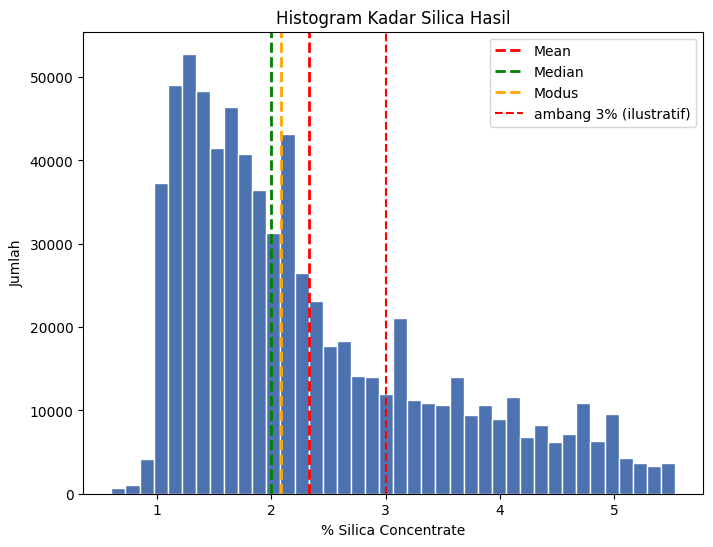

In [28]:
plt.figure(figsize=(8,6))

plt.hist(df["% Silica Concentrate"], bins=40,
         color="#4C72B0", edgecolor="white")
plt.axvline(df["% Silica Concentrate"].mean(), color="red",
                linestyle="--", linewidth=2, label="Mean")
plt.axvline(df["% Silica Concentrate"].median(), color="green",
                linestyle="--", linewidth=2, label="Median")
plt.axvline(df["% Silica Concentrate"].mode()[0], color="orange",
                linestyle="--", linewidth=2, label="Modus")
plt.axvline(3, color="red", linestyle="--", label="ambang 3% (ilustratif)")
plt.xlabel("% Silica Concentrate")
plt.ylabel("Jumlah")
plt.title("Histogram Kadar Silica Hasil")
plt.legend()
plt.show()

**Interpretation:**

Dari histogram **Kadar Silica Hasil** ini, saya melihat distribusi `% Silica Concentrate` condong ke kanan (*right-skewed*) dengan ekor yang memanjang ke arah nilai yang lebih tinggi.

Berikut poin-poin utama yang saya tangkap dari grafik:

* **Puncak sebaran di kadar rendah:**
  * Kepadatan tertinggi berada di kisaran **1% hingga 2%**, dengan puncak batang tertinggi sekitar **1,2%–1,3%** dan puncak kedua yang cukup menonjol di sekitar **2,1%**.


* **Posisi rata-rata, median, dan modus:**
  * **Median** (garis hijau putus-putus) berada di sekitar **2%**.
  * **Modus** (garis oranye putus-putus) berada sedikit di atas median, sekitar **2,1%**.
  * **Rata-rata** (garis merah putus-putus di kiri) berada lebih ke kanan, sekitar **2,3%**, karena tertarik oleh nilai-nilai tinggi di sisi kanan.




* **Ekor kanan & ambang 3%:**
  * Garis merah putus-putus di **3%** memisahkan mayoritas data yang lebih rendah dari sebaran di sebelah kanannya yang memanjang hingga sekitar **5,5%**, termasuk lonjakan lokal yang terlihat tepat setelah ambang **3%** (sekitar **3,1%**).



Menurut saya, visual ini mempertegas pola sebelumnya: proses paling sering menghasilkan kadar silika rendah di sekitar **1%–2%**, tetapi masih ada sejumlah catatan yang melebar ke atas **3%** hingga **5,5%**.

### b) Feed conditions: iron vs. silica content (side-by-side histograms)

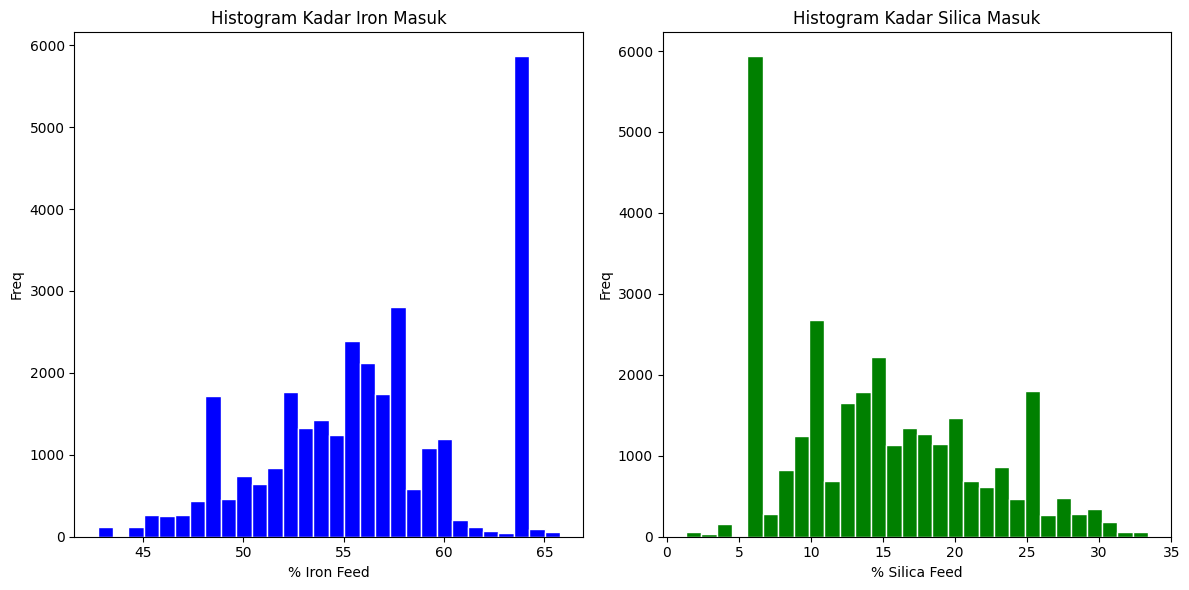

In [33]:
fig ,ax = plt.subplots(1,2, figsize=(12,6))

#ax 0
ax[0].hist(data['% Iron Feed'], bins=30,
           color="Blue", edgecolor="white")
ax[0].set_xlabel('% Iron Feed')
ax[0].set_ylabel('Freq')
ax[0].set_title('Histogram Kadar Iron Masuk')

#

#ax 1
ax[1].hist(data['% Silica Feed'], bins=30,
           color="green", edgecolor="white")
ax[1].set_xlabel('% Silica Feed')
ax[1].set_ylabel('Freq')
ax[1].set_title('Histogram Kadar Silica Masuk')

plt.tight_layout()

plt.show()

**Interpretation:**

Dari dua histogram kadar umpan masuk ini, saya melihat pola yang cukup mencolok:

* **Kadar Iron Masuk (`% Iron Feed`):**
  - Sebagian besar data berada di kisaran **48% hingga 60%**, tetapi ada satu lonjakan batang yang sangat tinggi mendekati **64%** (hampir **6.000** catatan), sejalan dengan nilai yang sering berulang pada statistik sebelumnya.

    
* **Kadar Silica Masuk (`% Silica Feed`):**
  - Sebarannya cukup lebar dari sekitar **2% sampai 33%**, dengan puncak tertinggi yang menonjol di sekitar **6%** (mendekati **6.000** catatan), lalu menyebar di kisaran **10%–26%** dengan beberapa puncak kecil.

Menurut saya, kualitas bahan baku yang masuk memang bervariasi, tetapi ada satu kondisi umpan tertentu (sekitar **64% iron** dan **6% silica**) yang jauh lebih sering muncul dibanding kondisi lainnya.

### c) Does dirty input → dirty output? (scatter)

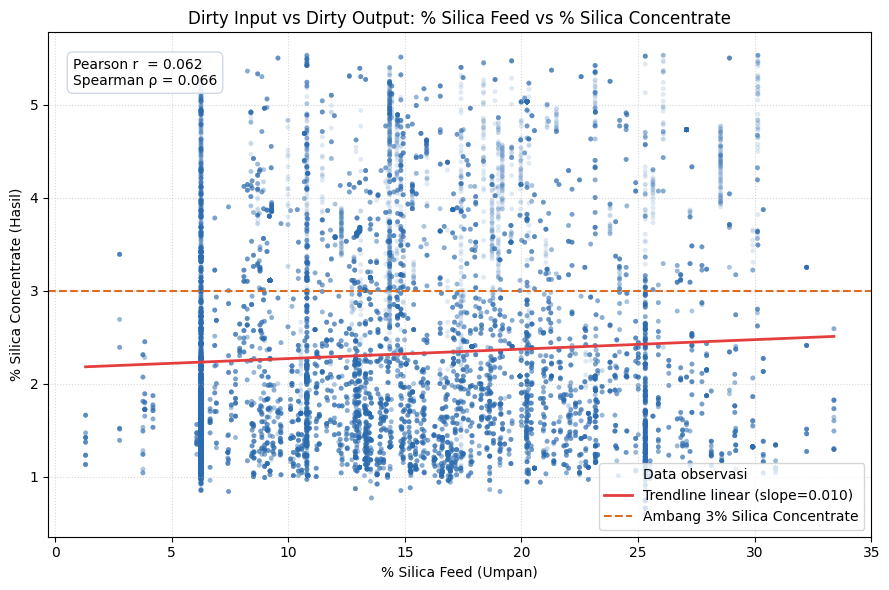

In [34]:
x_col = "% Silica Feed"
y_col = "% Silica Concentrate"
threshold = 3.0

# Hitung korelasi linear (Pearson) dan rank (Spearman)
r_pearson = data[x_col].corr(data[y_col], method="pearson")
r_spearman = data[x_col].corr(data[y_col], method="spearman")

fig, ax = plt.subplots(figsize=(9, 6))

# Scatter plot dengan transparansi agar kepadatan titik terlihat
ax.scatter(
    data[x_col],
    data[y_col],
    alpha=0.15,
    s=12,
    color="#2b6cb0",
    edgecolors="none",
    label="Data observasi",
)

# Garis regresi linear (trendline)
slope, intercept = np.polyfit(data[x_col], data[y_col], 1)
x_line = np.linspace(data[x_col].min(), data[x_col].max(), 200)
y_line = slope * x_line + intercept
ax.plot(
    x_line,
    y_line,
    color="#e53e3e",
    linewidth=2,
    label=f"Trendline linear (slope={slope:.3f})",
)

# Garis ambang batas ilustrasi 3% pada output
ax.axhline(
    threshold,
    color="#dd6b20",
    linestyle="--",
    linewidth=1.5,
    label=f"Ambang {threshold:.0f}% Silica Concentrate",
)

# Judul, label sumbu, dan anotasi korelasi
ax.set_title("Dirty Input vs Dirty Output: % Silica Feed vs % Silica Concentrate")
ax.set_xlabel("% Silica Feed (Umpan)")
ax.set_ylabel("% Silica Concentrate (Hasil)")
ax.grid(True, linestyle=":", alpha=0.5)

ax.text(
    0.03,
    0.95,
    f"Pearson r  = {r_pearson:.3f}\nSpearman ρ = {r_spearman:.3f}",
    transform=ax.transAxes,
    fontsize=10,
    verticalalignment="top",
    bbox=dict(
        boxstyle="round,pad=0.4", facecolor="white", edgecolor="#cbd5e0", alpha=0.9
    ),
)

ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

**Interpretation:**

Dari scatter plot ini, saya melihat jawabannya adalah **hampir tidak ada hubungan langsung yang kuat** antara kadar silika umpan (`% Silica Feed`) dan kadar silika hasil (`% Silica Concentrate`).

Berikut poin utama yang saya tangkap dari grafik:

* **Korelasi sangat lemah & garis hampir datar:**
  - Nilai **Pearson r = 0,062** dan **Spearman ρ = 0,066** dengan *slope* **0,010** menunjukkan garis merah nyaris mendatar—artinya umpan yang lebih kotor tidak otomatis membuat hasil akhir menjadi lebih kotor.


* **Garis-garis vertikal titik:**
  - Titik-titik membentuk garis vertikal pada nilai `% Silica Feed` tertentu (seperti sekitar **6%**, **11%**, **14%**, **20%**, dan **25%**), yang menandakan nilai umpan tersebut bertahan sama sementara hasil silikanya bergerak naik-turun dari sekitar **1% sampai lebih dari 5%**.


* **Hasil >3% terjadi di berbagai level umpan:**
  - Titik di atas garis oranye **3%** muncul merata di hampir seluruh rentang `% Silica Feed` (dari sekitar **6%** hingga **30%**), bukan hanya saat umpan sangat tinggi.



Menurut saya, ini memperkuat temuan sebelumnya: faktor pengendalian proses (seperti reagen, pH, dan kolom flotasi) jauh lebih menentukan apakah silika akhir bisa ditekan di bawah 3% dibanding kadar silika umpan semata.

### d) Distribution of silica yield by pH level (boxplot)

/tmp/ipykernel_765/1434206482.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


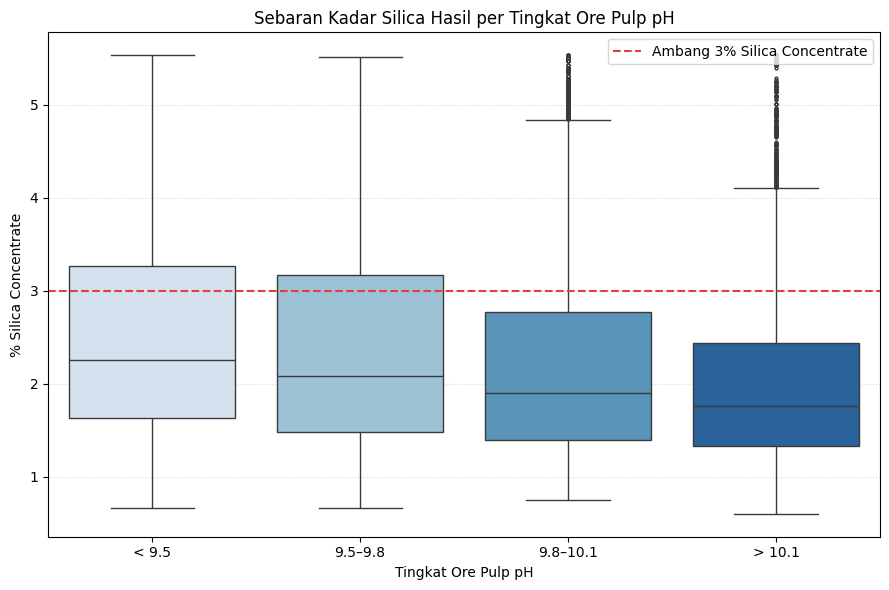

In [35]:
# Buat kelompok/tingkat pH agar mudah dibandingkan pada boxplot
bins = [8.5, 9.5, 9.8, 10.1, 11.0]
labels = ["< 9.5", "9.5–9.8", "9.8–10.1", "> 10.1"]

data["pH_level"] = pd.cut(
    data["Ore Pulp pH"], bins=bins, labels=labels, include_lowest=True
)

fig, ax = plt.subplots(figsize=(9, 6))

sns.boxplot(
    data=data,
    x="pH_level",
    y="% Silica Concentrate",
    palette="Blues",
    fliersize=2,
    ax=ax,
)

# Garis ambang batas ilustrasi 3%
ax.axhline(
    3.0,
    color="#e53e3e",
    linestyle="--",
    linewidth=1.5,
    label="Ambang 3% Silica Concentrate",
)

ax.set_title("Sebaran Kadar Silica Hasil per Tingkat Ore Pulp pH")
ax.set_xlabel("Tingkat Ore Pulp pH")
ax.set_ylabel("% Silica Concentrate")
ax.grid(True, axis="y", linestyle=":", alpha=0.5)
ax.legend(loc="upper right")

plt.tight_layout()
plt.show()

**Interpretation:**

Dari boxplot ini, saya melihat pola yang cukup jelas:
  - semakin tinggi tingkat `Ore Pulp pH`, kadar `% Silica Concentrate` cenderung makin rendah dan lebih sering berada di bawah batas `3%`.

* **Median makin turun:**
  - Nilai tengahnya turun bertahap dari sekitar **2,2%** (`< 9.5`), **2,1%** (`9.5–9.8`), **1,9%** (`9.8–10.1`), sampai sekitar **1,75%** (`> 10.1`).
* **Peluang melewati 3% makin kecil:** Di rentang pH `< 9.5` dan `9.5–9.8`, bagian atas kotak melewati garis merah **3%**, sedangkan di `9.8–10.1` dan `> 10.1` seluruh kotak berada di bawah **3%**.

* **Titik lonjakan tetap ada:**
  - Di pH yang lebih tinggi memang ada titik-titik *outlier* di atas 4%–5%, jadi pH tinggi bukan satu-satunya faktor yang bikin silika aman.


### Hipotesis Awal Saya

Menurut saya, **menjaga `Ore Pulp pH` di kisaran lebih tinggi (sekitar ≥ 9,8) berasosiasi dengan kadar silika hasil yang lebih rendah**, tetapi hal ini masih perlu saya uji lebih lanjut bersama variabel proses lain (seperti aliran reagen dan kondisi kolom flotasi) sebelum disimpulkan sebagai sebab-akibat.

## Conclusions & Insights

Berikut adalah rangkuman kesimpulan analisis dan rekomendasi praktis untuk operasional pabrik flotasi berdasarkan data yang telah kita pelajari:

### 📌 Kesimpulan Utama Analisis Data

1. **Kualitas Bahan Baku (*Feed*) Sangat Fluktuatif**
   - Kadar besi masuk (*Iron Feed*) rata-rata berada di angka **56,3%**, namun kadar pengotor silika masuk (*Silica Feed*) sangat bervariasi dengan rentang lebar dari **1,3% hingga 33,4%**. Meskipun demikian, ada satu kondisi umpan stabil yang paling sering masuk ke pabrik, yaitu di sekitar **64% Iron** dan **6% Silica**.

2. **Kadar Silika Umpan Bukan Penentu Tunggal Kualitas Akhir**
   - Berdasarkan analisis korelasi (*Pearson r = 0,062*) dan visualisasi *scatter plot*, **hampir tidak ada hubungan langsung yang kuat** antara tingkat kekotoran bahan baku (`% Silica Feed`) dengan tingkat kekotoran hasil akhir (`% Silica Concentrate`).
   - Kondisi hasil akhir yang tidak bersih (Silika > 3%) terjadi merata di hampir semua tingkat kadar silika umpan. Ini menunjukkan bahwa kegagalan menjaga kebersihan produk lebih disebabkan oleh **faktor pengendalian proses internal**, bukan semata-mata karena mendapatkan bahan baku yang kotor.

3. **Peran Kunci Reagen *Starch Flow***
   - Pada kondisi produk yang tidak bersih (Silika > 3%), rata-rata aliran reagen *starch* mengalami penurunan signifikan dari **2.931,66** menjadi **2.760,81** (berkurang sekitar 171 unit). Ini selaras dengan teori bahwa *starch* berfungsi sebagai *depressant* untuk menahan biji besi agar tidak ikut terangkat bersama busa pengotor.

4. **Pengaruh Krusial dari Tingkat Keasaman (`Ore Pulp pH`)**
   - Analisis *boxplot* menunjukkan tren yang sangat jelas: **semakin tinggi pH bubur bijih (*Ore Pulp pH*), kadar silika hasil akhir cenderung semakin rendah**.
   - Pada tingkat pH di atas **9,8**, probabilitas sebaran silika hasil untuk melewati batas ambang aman 3% berkurang secara drastis dibandingkan saat proses berjalan pada pH di bawah 9,5.

---

### 💡 Actionable Business Insights (Rekomendasi Operasional)

* **Optimalisasi Pengendalian pH (`Ore Pulp pH`):**
  - **Rekomendasi:** Tim operator pabrik harus memprioritaskan penjagaan stabilitas tingkat keasaman bubur bijih agar selalu berada **di atas pH 9,8** (ideal antara 9,8 s.d. 10,1).
  - **Dampak Bisnis:** Meminimalisir risiko produk gagal mutu secara signifikan dan memastikan kestabilan konsentrasi silika di bawah ambang batas 3%.

* **Otomatisasi & Standardisasi Aliran Reagen (*Starch Flow*):**
  - **Rekomendasi:** Diperlukan sistem kontrol otomatis (*feedback loop*) yang dapat segera meningkatkan pasokan *Starch Flow* ketika terdeteksi indikasi penurunan volume aliran, agar tidak sampai menyentuh angka kritis di bawah 2.800.
  - **Dampak Bisnis:** Mencegah penurunan efisiensi pemisahan mineral akibat kekurangan bahan pengikat (*depressant*) di dalam sel flotasi.

* **Peralihan Fokus dari Karakteristik Bahan Baku ke Kontrol Proses:**
  - **Rekomendasi:** Tim manajemen tidak perlu terlalu khawatir dengan fluktuasi pasokan kualitas bijih tambang (*Feed*) yang masuk. Fokus investasi teknologi dan pelatihan operator sebaiknya diarahkan pada **akurasi sensor kontrol proses** (pH, laju udara kolom flotasi, dan takaran kimia).
  - **Dampak Bisnis:** Menghemat biaya operasional yang tidak perlu untuk penyaringan awal bahan baku, dan memaksimalkan hasil produksi (*yield*) berkualitas tinggi secara konsisten.